In [ ]:
import os, sys, json, time, math, random, glob, platform, subprocess, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import sklearn
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold
from google.colab import files

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'
print('Python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
if DEVICE == 'cpu':
    print('PERINGATAN: GPU tidak aktif. Aktifkan Runtime > Change runtime type > GPU.')

OUT_DIR = '/content/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.precision', 4)

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
Device: cuda Tesla T4


In [ ]:
import os, glob, shutil, zipfile
from google.colab import files

DATA_DIR = '/content/data'
NEEDED = ['klasifikasi_train.npz', 'klasifikasi_test.npz',
          'klasifikasi_train_meta.csv', 'klasifikasi_test_meta.csv']
os.makedirs(DATA_DIR, exist_ok=True)

def _rapikan_upload():
    for f in NEEDED:
        tujuan = os.path.join(DATA_DIR, f)
        if os.path.exists(f) and not os.path.exists(tujuan):
            shutil.move(f, tujuan)
    for zp in glob.glob('*.zip'):
        with zipfile.ZipFile(zp) as z:
            for f in NEEDED:
                if f in z.namelist() and not os.path.exists(os.path.join(DATA_DIR, f)):
                    z.extract(f, DATA_DIR)

def _kurang():
    return [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]

_rapikan_upload()
if _kurang():
    print('Silakan upload file berikut:', _kurang())
    uploaded = files.upload()
    _rapikan_upload()
assert not _kurang(), f'Masih kurang: {_kurang()} -> jalankan sel ini lagi dan upload file tersebut'
for f in NEEDED:
    print(f'{f:30s} {os.path.getsize(os.path.join(DATA_DIR, f))/1e6:8.1f} MB')

Silakan upload file berikut: ['klasifikasi_train.npz', 'klasifikasi_test.npz', 'klasifikasi_train_meta.csv', 'klasifikasi_test_meta.csv']


Saving klasifikasi_test.npz to klasifikasi_test.npz
Saving klasifikasi_test_meta.csv to klasifikasi_test_meta.csv
Saving klasifikasi_train.npz to klasifikasi_train.npz
Saving klasifikasi_train_meta.csv to klasifikasi_train_meta.csv
klasifikasi_train.npz             179.3 MB
klasifikasi_test.npz               61.1 MB
klasifikasi_train_meta.csv          1.8 MB
klasifikasi_test_meta.csv           0.5 MB


## Konfigurasi

In [ ]:
QUICK = False

CLASSES = ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
N_CLS = len(CLASSES)

CFG = dict(
    epochs     = 3 if QUICK else 20,
    oof_epochs = 2 if QUICK else 8,
    batch      = 256,
    lr         = 2e-3,
    wd         = 1e-4,
    ls         = 0.0,
    mod_drop   = 0.15,
    bright_aug = False,
    norm       = 'global',
)
SPLIT_SEED = 42
FINAL_SEEDS = [0, 1, 2]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
set_seed(SPLIT_SEED)
print(CFG)

{'epochs': 20, 'oof_epochs': 8, 'batch': 256, 'lr': 0.002, 'wd': 0.0001, 'ls': 0.0, 'mod_drop': 0.15, 'bright_aug': False, 'norm': 'global'}


In [ ]:

tr_meta = pd.read_csv(f'{DATA_DIR}/klasifikasi_train_meta.csv')
te_meta = pd.read_csv(f'{DATA_DIR}/klasifikasi_test_meta.csv')
_d  = np.load(f'{DATA_DIR}/klasifikasi_train.npz')
_dt = np.load(f'{DATA_DIR}/klasifikasi_test.npz')
X_img, X_sen = _d['gambar'], _d['sensor'].astype(np.float32)
T_img, T_sen = _dt['gambar'], _dt['sensor'].astype(np.float32)

assert (tr_meta['indeks'].values == np.arange(len(tr_meta))).all()
assert (te_meta['indeks'].values == np.arange(len(te_meta))).all()

y_all   = tr_meta['kelas'].map({c: i for i, c in enumerate(CLASSES)}).values.astype(np.int64)
line_tr = (tr_meta['lini'] == 'B').astype(int).values
line_te = (te_meta['lini'] == 'B').astype(int).values
present_tr = ~np.isnan(X_sen).all(axis=(1, 2))
present_te = ~np.isnan(T_sen).all(axis=(1, 2))
SEN_NAMES = ['suhu (C)', 'getaran (rel)', 'arus (A)']

print('train:', X_img.shape, X_sen.shape, '| test:', T_img.shape, T_sen.shape)
tr_meta.head()

train: (48000, 64, 64) (48000, 3, 128) | test: (16000, 64, 64) (16000, 3, 128)


,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal
3,3,U696502,A,siang,M06,B085,noda
4,4,U272751,B,siang,M08,B106,normal


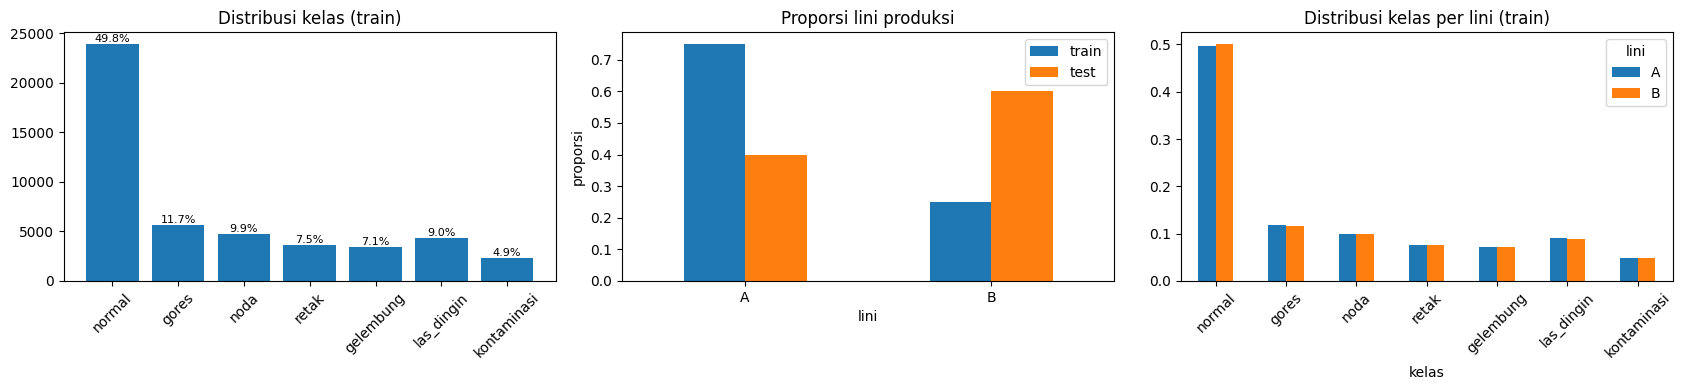

Mesin per lini (train):
id_mesin   M01   M02   M03   M04   M05   M06   M07   M08   M09   M10   M11  \
lini                                                                         
A         5976  6058  5986  6134  6040  5770     0     0     0     0     0   
B            0     0     0     0     0     0  2016  1981  2083  1943  1994   

id_mesin   M12  
lini            
A            0  
B         2019  

Proporsi shift  train: {'malam': 0.335, 'siang': 0.334, 'pagi': 0.33} 
                test : {'pagi': 0.337, 'malam': 0.334, 'siang': 0.329}
Batch material unik train/test: 150 150


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
vc = tr_meta['kelas'].value_counts().reindex(CLASSES)
ax[0].bar(CLASSES, vc.values, color='tab:blue'); ax[0].set_title('Distribusi kelas (train)')
ax[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(vc.values): ax[0].text(i, v, f'{v/len(tr_meta):.1%}', ha='center', va='bottom', fontsize=8)

lt = pd.DataFrame({'train': tr_meta['lini'].value_counts(normalize=True),
                   'test': te_meta['lini'].value_counts(normalize=True)})
lt.plot.bar(ax=ax[1], rot=0); ax[1].set_title('Proporsi lini produksi'); ax[1].set_ylabel('proporsi')

ct = pd.crosstab(tr_meta['kelas'], tr_meta['lini'], normalize='columns').reindex(CLASSES)
ct.plot.bar(ax=ax[2], rot=45); ax[2].set_title('Distribusi kelas per lini (train)')
plt.tight_layout(); plt.show()

print('Mesin per lini (train):'); print(pd.crosstab(tr_meta['id_mesin'], tr_meta['lini']).T)
print('\nProporsi shift  train:', tr_meta['shift'].value_counts(normalize=True).round(3).to_dict(),
      '\n                test :', te_meta['shift'].value_counts(normalize=True).round(3).to_dict())
print('Batch material unik train/test:', tr_meta['batch_material'].nunique(), te_meta['batch_material'].nunique())

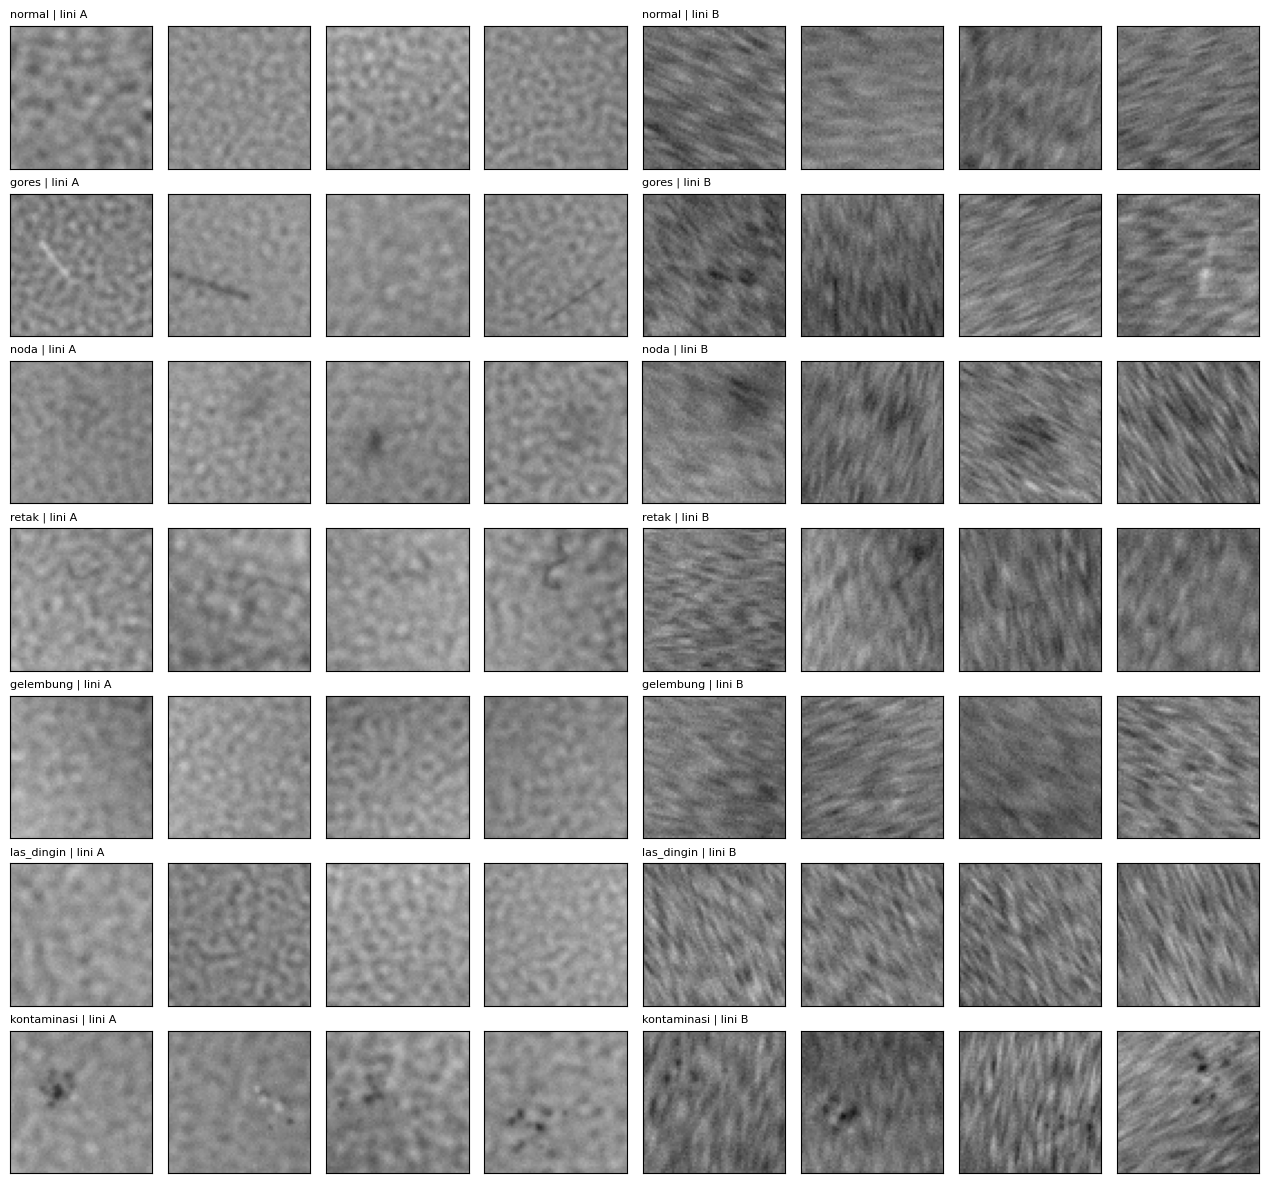

In [ ]:
rng = np.random.default_rng(0)
n_per = 4
fig, ax = plt.subplots(N_CLS, 2 * n_per, figsize=(2 * n_per * 1.6, N_CLS * 1.7))
for i, c in enumerate(CLASSES):
    for L in (0, 1):
        idx = np.where((y_all == i) & (line_tr == L))[0]
        for j, k in enumerate(rng.choice(idx, n_per, replace=False)):
            a = ax[i, L * n_per + j]
            a.imshow(X_img[k], cmap='gray', vmin=0, vmax=255); a.set_xticks([]); a.set_yticks([])
            if j == 0: a.set_title(f'{c} | lini {"AB"[L]}', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

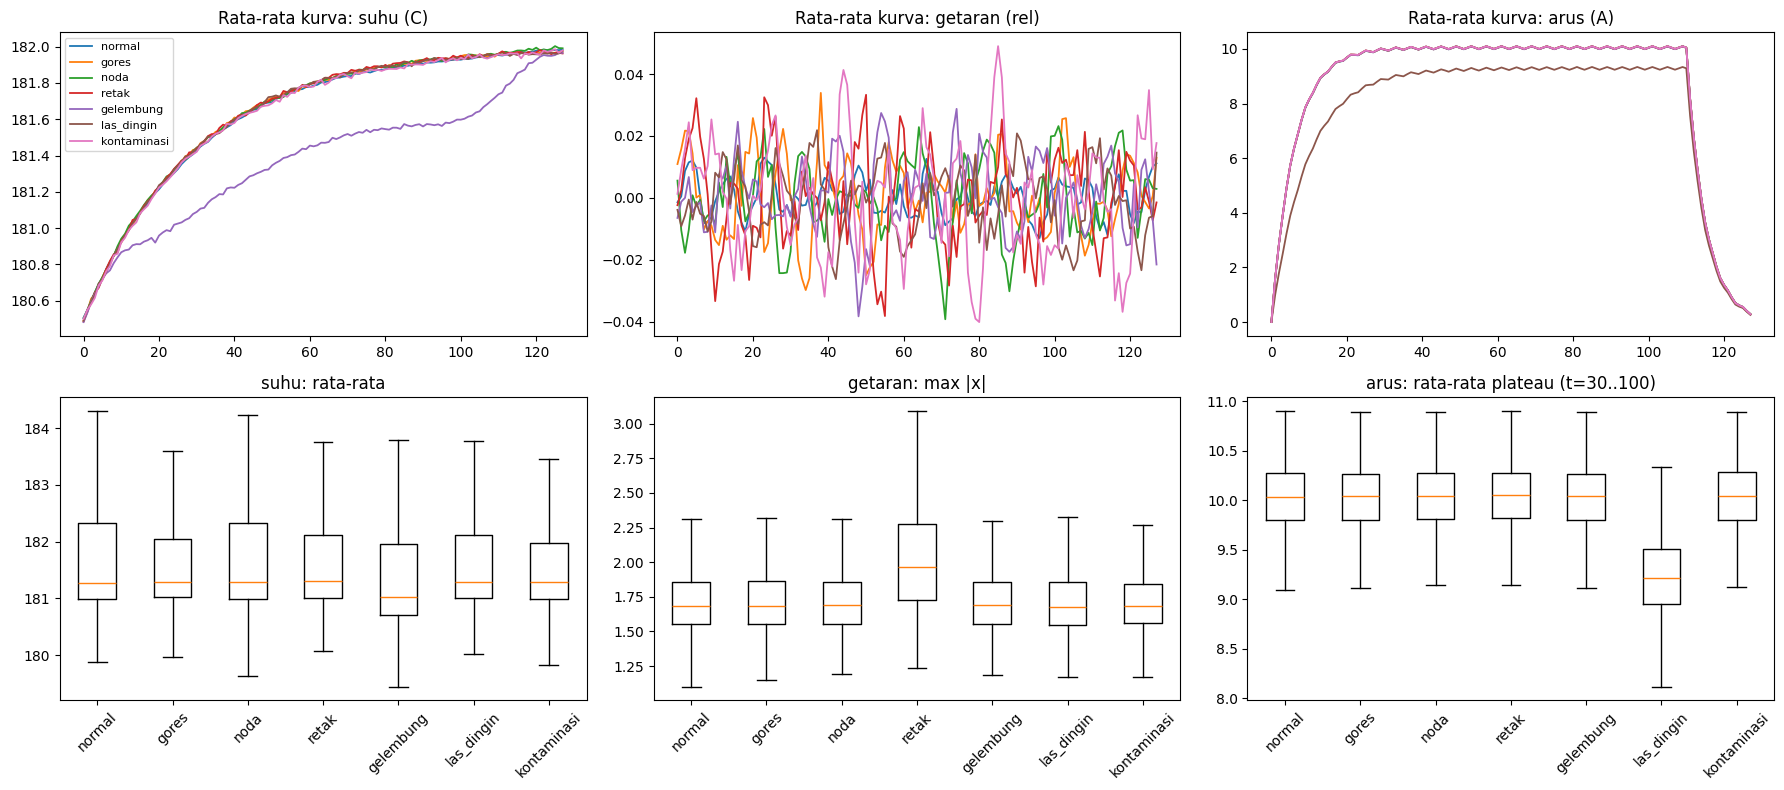

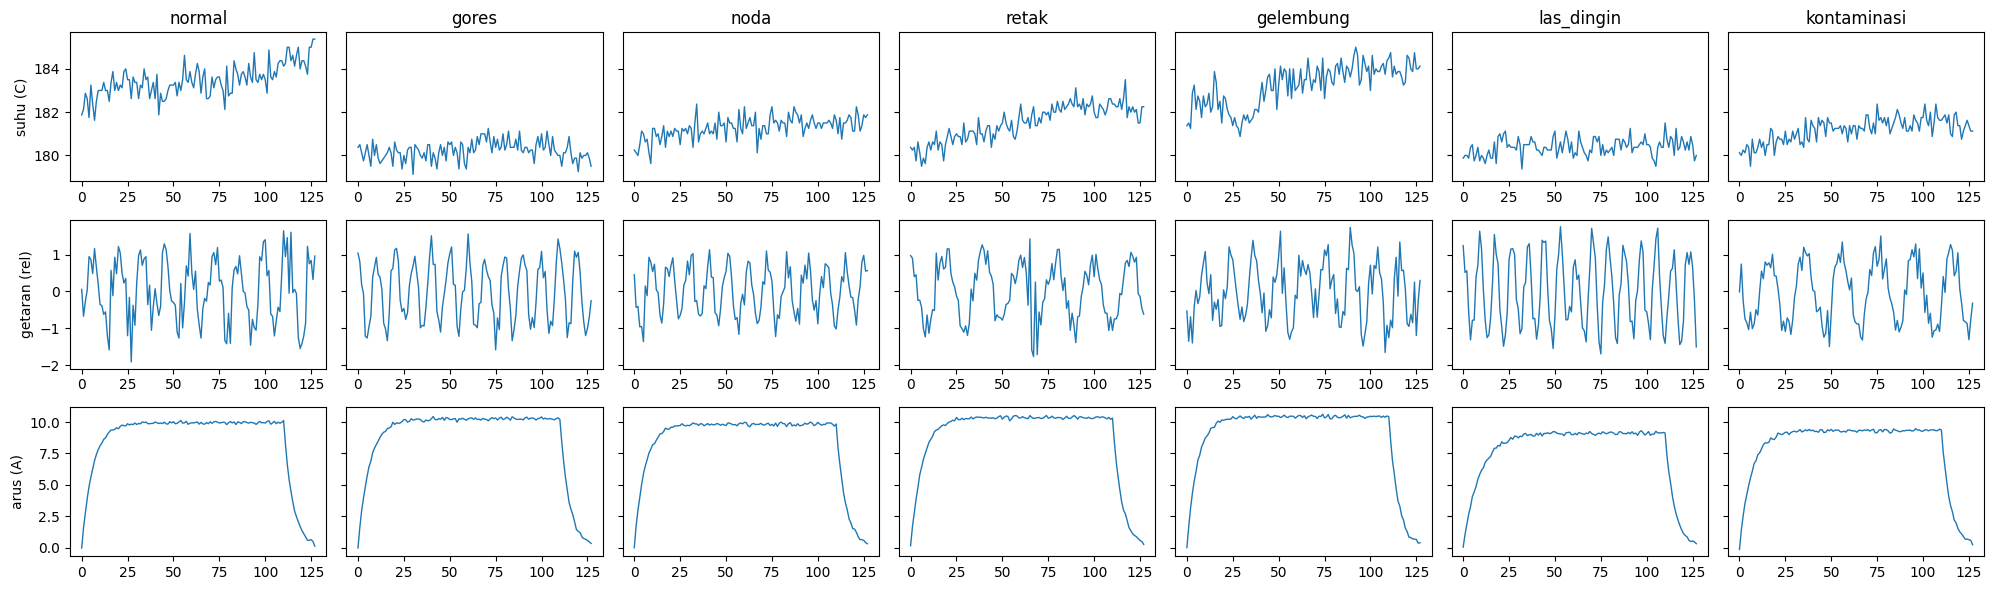

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for ch in range(3):
    for i, c in enumerate(CLASSES):
        m = y_all == i
        ax[0, ch].plot(np.nanmean(X_sen[m, ch], axis=0), label=c, lw=1.3)
    ax[0, ch].set_title(f'Rata-rata kurva: {SEN_NAMES[ch]}')
ax[0, 0].legend(fontsize=8)

# statistik per unit
with np.errstate(all='ignore'):
    feats = {'suhu: rata-rata': np.nanmean(X_sen[:, 0], 1),
             'getaran: max |x|': np.nanmax(np.abs(X_sen[:, 1]), 1),
             'arus: rata-rata plateau (t=30..100)': np.nanmean(X_sen[:, 2, 30:100], 1)}
for ch, (nm, v) in enumerate(feats.items()):
    data = [v[(y_all == i) & ~np.isnan(v)] for i in range(N_CLS)]
    ax[1, ch].boxplot(data, showfliers=False); ax[1, ch].set_title(nm)
    ax[1, ch].set_xticks(range(1, N_CLS + 1)); ax[1, ch].set_xticklabels(CLASSES, rotation=45)
plt.tight_layout(); plt.show()

# contoh satu unit per kelas
fig, ax = plt.subplots(3, N_CLS, figsize=(20, 6), sharey='row')
for i, c in enumerate(CLASSES):
    k = np.where((y_all == i) & present_tr & ~np.isnan(X_sen).any(axis=(1, 2)))[0][0]
    for ch in range(3):
        ax[ch, i].plot(X_sen[k, ch], lw=1)
        if ch == 0: ax[ch, i].set_title(c)
        if i == 0: ax[ch, i].set_ylabel(SEN_NAMES[ch])
plt.tight_layout(); plt.show()

In [ ]:
def missing_summary(S):
    n = np.isnan(S).all(axis=2)              # (N,3) kanal yang hilang
    k = n.sum(1)
    return pd.Series({'semua kanal hilang': (k == 3).mean(), '1 kanal hilang': (k == 1).mean(),
                      '2 kanal hilang': (k == 2).mean(), 'lengkap': (k == 0).mean()})

ms = pd.DataFrame({'train': missing_summary(X_sen), 'test': missing_summary(T_sen)})
display(ms.style.format('{:.2%}'))

ch_miss = pd.DataFrame(np.isnan(X_sen).all(axis=2).mean(0)[None], columns=SEN_NAMES, index=['train: proporsi kanal hilang'])
display(ch_miss.style.format('{:.2%}'))

miss_any = np.isnan(X_sen).any(axis=(1, 2))
tab = pd.DataFrame({'sensor hilang (semua)': pd.Series(~present_tr).groupby(tr_meta['kelas']).mean(),
                    'ada kanal hilang': pd.Series(miss_any).groupby(tr_meta['kelas']).mean()}).reindex(CLASSES)
tab.loc['--lini A'] = [(~present_tr)[line_tr == 0].mean(), miss_any[line_tr == 0].mean()]
tab.loc['--lini B'] = [(~present_tr)[line_tr == 1].mean(), miss_any[line_tr == 1].mean()]
display(tab.style.format('{:.2%}'))

,train,test
semua kanal hilang,4.90%,5.08%
1 kanal hilang,3.15%,3.03%
2 kanal hilang,0.00%,0.00%
lengkap,91.95%,91.89%


,suhu (C),getaran (rel),arus (A)
train: proporsi kanal hilang,5.95%,5.93%,5.96%


,sensor hilang (semua),ada kanal hilang
kelas,,
normal,4.76%,8.09%
gores,5.18%,8.50%
noda,5.17%,7.81%
retak,5.55%,8.49%
gelembung,5.10%,8.02%
las_dingin,4.70%,7.66%
kontaminasi,4.16%,7.13%
--lini A,4.86%,8.09%
--lini B,5.02%,7.91%


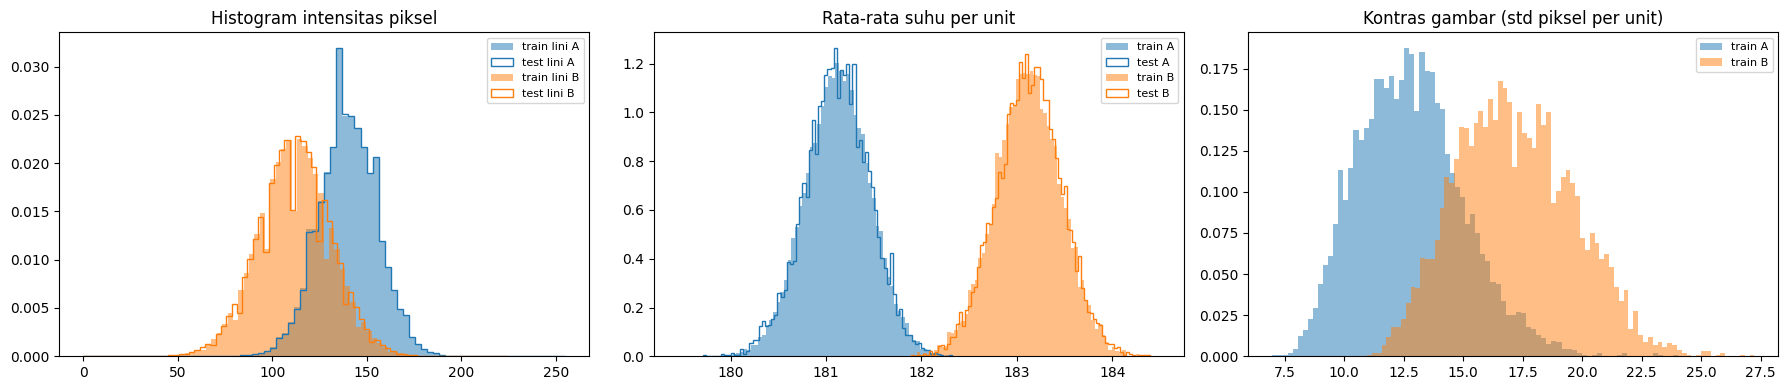

,set,lini,n,proporsi,mean piksel,std piksel,mean suhu (C),mean getaran (rel),mean arus (A)
0,train,A,35964,0.7492,139.7907,15.3307,181.1197,1.1782e-04,8.4727
1,train,B,12036,0.2507,111.7319,19.1146,183.1155,4.3011e-04,8.4157
2,test,A,6393,0.3996,139.8880,15.2496,181.1160,-9.3335e-05,8.4774
3,test,B,9607,0.6004,111.6542,19.0665,183.1272,6.0441e-04,8.4127


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for L, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
    ax[0].hist(X_img[line_tr == L][:3000].reshape(-1), bins=80, alpha=.5, density=True, color=col, label=f'train lini {"AB"[L]}')
    ax[0].hist(T_img[line_te == L][:3000].reshape(-1), bins=80, histtype='step', density=True, color=col, label=f'test lini {"AB"[L]}')
    t = np.nanmean(X_sen[line_tr == L, 0], 1); ax[1].hist(t[~np.isnan(t)], bins=80, alpha=.5, density=True, color=col, label=f'train {"AB"[L]}')
    t = np.nanmean(T_sen[line_te == L, 0], 1); ax[1].hist(t[~np.isnan(t)], bins=80, histtype='step', density=True, color=col, label=f'test {"AB"[L]}')
    ax[2].hist(X_img[line_tr == L][:5000].reshape(-1, 64 * 64).std(1), bins=80, alpha=.5, density=True, color=col, label=f'train {"AB"[L]}')
ax[0].set_title('Histogram intensitas piksel'); ax[0].legend(fontsize=8)
ax[1].set_title('Rata-rata suhu per unit'); ax[1].legend(fontsize=8)
ax[2].set_title('Kontras gambar (std piksel per unit)'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for nm, I, S, Ln in [('train', X_img, X_sen, line_tr), ('test', T_img, T_sen, line_te)]:
    for L in (0, 1):
        m = Ln == L
        rows.append({'set': nm, 'lini': 'AB'[L], 'n': m.sum(), 'proporsi': m.mean(),
                     'mean piksel': I[m].mean(), 'std piksel': I[m][:5000].std(),
                     **{f'mean {SEN_NAMES[c]}': np.nanmean(S[m, c]) for c in range(3)}})
display(pd.DataFrame(rows))

In [ ]:
strat = y_all * 2 + line_tr
idx_tr, idx_va = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=strat, random_state=SPLIT_SEED)
print('train', len(idx_tr), '| val', len(idx_va), '| proporsi lini B val:', line_tr[idx_va].mean().round(3))

P_B_TEST = line_te.mean()
P_B_VAL  = line_tr[idx_va].mean()

def compute_stats(idx, mode, rng_seed=0):
    rng = np.random.default_rng(rng_seed)
    def one(sel):
        sub = rng.choice(sel, min(len(sel), 6000), replace=False)
        im = X_img[sub].astype(np.float32)
        return dict(img_m=float(im.mean()), img_s=float(im.std()),
                    sen_m=np.nanmean(X_sen[sel], axis=(0, 2)), sen_s=np.nanstd(X_sen[sel], axis=(0, 2)))
    if mode == 'global':
        g = one(idx)
        return {0: g, 1: g}
    return {L: one(idx[line_tr[idx] == L]) for L in (0, 1)}

def to_tensors(img_u8, sen, lines, st):
    img = img_u8.astype(np.float32)
    sen = sen.copy()
    for L in (0, 1):
        m = lines == L
        img[m] = (img[m] - st[L]['img_m']) / st[L]['img_s']
        sen[m] = (sen[m] - st[L]['sen_m'][None, :, None]) / st[L]['sen_s'][None, :, None]
    mask = (~np.isnan(sen)).astype(np.float32)
    sen = np.nan_to_num(sen, nan=0.0)
    sen6 = np.concatenate([sen, mask], axis=1)
    return (torch.from_numpy(img[:, None]).half().to(DEVICE),
            torch.from_numpy(sen6).half().to(DEVICE))

_DATA_CACHE = {}
def get_data(mode):
    if mode not in _DATA_CACHE:
        _DATA_CACHE.clear(); torch.cuda.empty_cache()
        st = compute_stats(idx_tr, mode)
        im, se = to_tensors(X_img, X_sen, line_tr, st)
        tim, tse = to_tensors(T_img, T_sen, line_te, st)
        _DATA_CACHE[mode] = dict(img=im, sen=se, y=torch.from_numpy(y_all).to(DEVICE),
                                 test=dict(img=tim, sen=tse), stats=st)
    return _DATA_CACHE[mode]

cnt = np.bincount(y_all[idx_tr], minlength=N_CLS)
CLS_W = torch.tensor((cnt.max() / cnt) ** 0.5, dtype=torch.float32, device=DEVICE)
CLS_W = CLS_W / CLS_W.mean()
print('class weights:', dict(zip(CLASSES, CLS_W.cpu().numpy().round(2))))

def augment(img, sen, cfg):
    B, dev = img.shape[0], img.device
    def coin(): return (torch.rand(B, device=dev) < 0.5)[:, None, None, None]
    img = torch.where(coin(), img.flip(3), img)
    img = torch.where(coin(), img.flip(2), img)
    img = torch.where(coin(), img.transpose(2, 3), img)
    if cfg['bright_aug']:
        a = 1 + 0.25 * (2 * torch.rand(B, 1, 1, 1, device=dev) - 1)
        b = 0.5 * (2 * torch.rand(B, 1, 1, 1, device=dev) - 1)
        img = img * a + b
    sv, sm = sen[:, :3], sen[:, 3:]
    sv = sv + 0.05 * torch.randn_like(sv) * sm
    if cfg['mod_drop'] > 0:
        keep = (torch.rand(B, device=dev) >= cfg['mod_drop']).float()[:, None, None]
        sv, sm = sv * keep, sm * keep
    return img, torch.cat([sv, sm], 1)

train 38400 | val 9600 | proporsi lini B val: 0.251
class weights: {'normal': np.float32(0.44), 'gores': np.float32(0.9), 'noda': np.float32(0.98), 'retak': np.float32(1.12), 'gelembung': np.float32(1.15), 'las_dingin': np.float32(1.03), 'kontaminasi': np.float32(1.39)}


In [ ]:
def gpool(x):
    x = x.flatten(2)
    return torch.cat([x.mean(-1), x.amax(-1)], 1)

def cbr2(i, o): return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
def cbr1(i, o, k): return [nn.Conv1d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm1d(o), nn.ReLU(inplace=True)]

class ImgEnc(nn.Module):
    def __init__(self, w=32):
        super().__init__()
        self.net = nn.Sequential(
            *cbr2(1, w), nn.MaxPool2d(2),
            *cbr2(w, 2 * w), *cbr2(2 * w, 2 * w), nn.MaxPool2d(2),
            *cbr2(2 * w, 4 * w), *cbr2(4 * w, 4 * w), nn.MaxPool2d(2),
            *cbr2(4 * w, 8 * w), *cbr2(8 * w, 8 * w))
        self.out_ch = 8 * w
    def forward(self, x): return self.net(x)

class SenEnc(nn.Module):
    def __init__(self, cin=6, w=64):
        super().__init__()
        self.net = nn.Sequential(
            *cbr1(cin, w, 7), *cbr1(w, w, 5), nn.MaxPool1d(2),
            *cbr1(w, 2 * w, 5), *cbr1(2 * w, 2 * w, 3), nn.MaxPool1d(2),
            *cbr1(2 * w, 4 * w, 3), *cbr1(4 * w, 4 * w, 3), nn.MaxPool1d(2))
        self.out_ch = 4 * w
    def forward(self, x): return self.net(x)

def mlp_head(i, n=N_CLS, d=128):
    return nn.Sequential(nn.Dropout(0.3), nn.Linear(i, d), nn.ReLU(inplace=True), nn.Dropout(0.2), nn.Linear(d, n))

class Net(nn.Module):
    def __init__(self, mode, d=128):
        super().__init__()
        self.mode = mode
        self.use_img, self.use_sen = mode != 'sen', mode != 'img'
        if self.use_img: self.ie = ImgEnc()
        if self.use_sen:
            self.se = SenEnc()
            self.miss = nn.Parameter(torch.zeros(2 * self.se.out_ch))
        if mode in ('img', 'sen'):
            self.head = mlp_head(512)
        elif mode == 'concat':
            self.head = mlp_head(512 + 512 + 1)
        elif mode == 'late':
            self.hi, self.hs = mlp_head(512), mlp_head(512)
        elif mode == 'xattn':
            self.pi, self.ps = nn.Conv2d(256, d, 1), nn.Conv1d(256, d, 1)
            self.pos_i = nn.Parameter(torch.randn(1, 64, d) * .02)
            self.pos_s = nn.Parameter(torch.randn(1, 16, d) * .02)
            self.null = nn.Parameter(torch.randn(1, 1, d) * .02)
            self.a_is = nn.MultiheadAttention(d, 4, dropout=0.1, batch_first=True)
            self.a_si = nn.MultiheadAttention(d, 4, dropout=0.1, batch_first=True)
            self.ln_i, self.ln_s = nn.LayerNorm(d), nn.LayerNorm(d)
            self.head = mlp_head(4 * d + 1)

    def forward(self, img, sen):
        p = (sen[:, 3:].flatten(1).sum(1) > 0).float()
        pc = p[:, None]
        if self.mode == 'img':
            return self.head(gpool(self.ie(img)))
        fs = self.se(sen)
        zs = gpool(fs) * pc + (1 - pc) * self.miss
        if self.mode == 'sen':
            return self.head(zs)
        fi = self.ie(img)
        if self.mode == 'concat':
            return self.head(torch.cat([gpool(fi), zs, pc], 1))
        if self.mode == 'late':
            return self.hi(gpool(fi)) + pc * self.hs(gpool(fs))

        B = img.shape[0]
        ti = self.pi(fi).flatten(2).transpose(1, 2) + self.pos_i
        ts = self.ps(fs).transpose(1, 2) + self.pos_s
        kv = torch.cat([self.null.expand(B, -1, -1).to(ts.dtype), ts], 1)
        kpm = torch.zeros(B, kv.shape[1], dtype=torch.bool, device=img.device)
        kpm[:, 1:] = (p < 0.5)[:, None]
        ai, _ = self.a_is(ti, kv, kv, key_padding_mask=kpm, need_weights=False)
        ti = self.ln_i(ti + ai)
        as_, _ = self.a_si(ts, ti, ti, need_weights=False)
        ts = self.ln_s(ts + as_)
        zi = torch.cat([ti.mean(1), ti.amax(1)], 1)
        zs = torch.cat([ts.mean(1), ts.amax(1)], 1) * pc
        return self.head(torch.cat([zi, zs, pc], 1))

for m in ['img', 'sen', 'concat', 'late', 'xattn']:
    net = Net(m)
    print(f'{m:7s} params: {sum(p.numel() for p in net.parameters())/1e6:.2f} M')

img     params: 1.23 M
sen     params: 0.48 M
concat  params: 1.71 M
late    params: 1.71 M
xattn   params: 1.85 M


In [ ]:
RESULTS, PROBS, HISTS, MODELS = {}, {}, {}, {}

@torch.no_grad()
def predict(model, D, idx, drop_sensor=False, tta=False, bs=1024):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        b = torch.as_tensor(idx[i:i + bs], device=DEVICE)
        xi, xs = D['img'][b].float(), D['sen'][b].float()
        if drop_sensor: xs = torch.zeros_like(xs)
        views = [xi] if not tta else [xi, xi.flip(3), xi.flip(2), xi.transpose(2, 3)]
        pr = 0
        for v in views:
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                pr = pr + model(v, xs).float().softmax(1)
        out.append((pr / len(views)).cpu())
    return torch.cat(out).numpy()

def macro_f1(yt, yp, w=None):
    return f1_score(yt, yp, average='macro', labels=list(range(N_CLS)), sample_weight=w, zero_division=0)

def evaluate(probs, idx, name=None, verbose=True):
    yt, yp, ln = y_all[idx], probs.argmax(1), line_tr[idx]
    w = np.where(ln == 1, P_B_TEST / P_B_VAL, (1 - P_B_TEST) / (1 - P_B_VAL))
    miss = ~present_tr[idx]
    r = dict(macro_f1=macro_f1(yt, yp), f1_testmix=macro_f1(yt, yp, w),
             f1_A=macro_f1(yt[ln == 0], yp[ln == 0]), f1_B=macro_f1(yt[ln == 1], yp[ln == 1]),
             f1_sensor_hilang=macro_f1(yt[miss], yp[miss]), acc=(yt == yp).mean())
    r['per_class'] = f1_score(yt, yp, average=None, labels=list(range(N_CLS)), zero_division=0)
    if name is not None:
        RESULTS[name] = r; PROBS[name] = probs
    if verbose:
        print(f"[{name}] macroF1={r['macro_f1']:.4f} | testmix={r['f1_testmix']:.4f} | A={r['f1_A']:.4f} "
              f"| B={r['f1_B']:.4f} | sensor-hilang={r['f1_sensor_hilang']:.4f}")
    return r

def results_table(names=None, extra=True):
    names = names or list(RESULTS)
    df = pd.DataFrame({n: {k: v for k, v in RESULTS[n].items() if k != 'per_class'} for n in names}).T
    return df

def train_model(mode, cfg, train_idx, val_idx=None, seed=0, verbose=True, tag=None):
    set_seed(seed)
    D = get_data(cfg['norm'])
    model = Net(mode).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    spe = len(train_idx) // cfg['batch']
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=cfg['epochs'] * spe, pct_start=0.2)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    gen = torch.Generator().manual_seed(seed)
    tidx = torch.as_tensor(train_idx)
    hist = []
    t0 = time.time()
    for ep in range(cfg['epochs']):
        model.train(); perm = tidx[torch.randperm(len(tidx), generator=gen)]
        tot, n = 0.0, 0
        for s in range(spe):
            b = perm[s * cfg['batch']:(s + 1) * cfg['batch']].to(DEVICE)
            xi, xs = augment(D['img'][b].float(), D['sen'][b].float(), cfg)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(xi, xs)
            loss = F.cross_entropy(out.float(), D['y'][b], weight=CLS_W, label_smoothing=cfg['ls'])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(b); n += len(b)
        h = dict(epoch=ep + 1, train_loss=tot / n)
        if val_idx is not None:
            pv = predict(model, D, val_idx)
            yv = y_all[val_idx]
            h['val_loss'] = float(-np.log(pv[np.arange(len(yv)), yv] + 1e-8).mean())
            h['val_f1'] = macro_f1(yv, pv.argmax(1))
        hist.append(h)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0 or ep + 1 == cfg['epochs']):
            print(f"  [{tag or mode}] ep {ep+1:2d}/{cfg['epochs']} " + ' '.join(f'{k}={v:.4f}' for k, v in h.items() if k != 'epoch')
                  + f' ({time.time()-t0:.0f}s)')
    if tag: HISTS[tag] = pd.DataFrame(hist)
    return model, pd.DataFrame(hist)

def run(tag, mode, seed=0, train_idx=None, **over):
    cfg = {**CFG, **over}
    model, hist = train_model(mode, cfg, idx_tr if train_idx is None else train_idx, idx_va, seed=seed, tag=tag)
    probs = predict(model, get_data(cfg['norm']), idx_va)
    evaluate(probs, idx_va, tag)
    MODELS[tag] = model
    return model

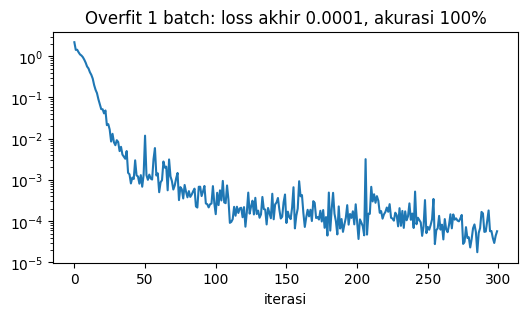

In [ ]:
set_seed(0)
D = get_data('global')
b = torch.as_tensor(idx_tr[:64], device=DEVICE)
xi, xs, yb = D['img'][b].float(), D['sen'][b].float(), D['y'][b]
m_sanity = Net('concat').to(DEVICE)
opt = torch.optim.Adam(m_sanity.parameters(), lr=1e-3)
losses = []
for it in range(300):
    m_sanity.train()
    loss = F.cross_entropy(m_sanity(xi, xs), yb)
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
m_sanity.eval()
with torch.no_grad(): acc = (m_sanity(xi, xs).argmax(1) == yb).float().mean().item()
plt.figure(figsize=(6, 3)); plt.semilogy(losses); plt.title(f'Overfit 1 batch: loss akhir {losses[-1]:.4f}, akurasi {acc:.0%}')
plt.xlabel('iterasi'); plt.show()
del m_sanity

In [ ]:
for mode in ['concat', 'late', 'xattn']:
    run(f'fusi_{mode}', mode)
display(results_table([f'fusi_{m}' for m in ['concat', 'late', 'xattn']]))

BEST_MODE = max(['concat', 'late', 'xattn'], key=lambda m: RESULTS[f'fusi_{m}']['f1_testmix'])
print('Strategi fusi terbaik (f1_testmix):', BEST_MODE)

  [fusi_concat] ep  1/20 train_loss=1.4204 val_loss=0.9200 val_f1=0.6587 (9s)
  [fusi_concat] ep  5/20 train_loss=0.6769 val_loss=0.5454 val_f1=0.8063 (38s)
  [fusi_concat] ep 10/20 train_loss=0.5551 val_loss=0.4371 val_f1=0.8491 (76s)
  [fusi_concat] ep 15/20 train_loss=0.4654 val_loss=0.4355 val_f1=0.8500 (114s)
  [fusi_concat] ep 20/20 train_loss=0.3978 val_loss=0.3855 val_f1=0.8708 (153s)
[fusi_concat] macroF1=0.8708 | testmix=0.8315 | A=0.8987 | B=0.7855 | sensor-hilang=0.6557
  [fusi_late] ep  1/20 train_loss=1.4466 val_loss=0.9114 val_f1=0.6803 (8s)
  [fusi_late] ep  5/20 train_loss=0.6802 val_loss=0.6199 val_f1=0.7907 (39s)
  [fusi_late] ep 10/20 train_loss=0.5643 val_loss=0.4736 val_f1=0.8389 (79s)
  [fusi_late] ep 15/20 train_loss=0.4677 val_loss=0.4352 val_f1=0.8544 (118s)
  [fusi_late] ep 20/20 train_loss=0.3862 val_loss=0.4029 val_f1=0.8631 (157s)
[fusi_late] macroF1=0.8631 | testmix=0.8222 | A=0.8919 | B=0.7742 | sensor-hilang=0.6360
  [fusi_xattn] ep  1/20 train_loss=1.4

,macro_f1,f1_testmix,f1_A,f1_B,f1_sensor_hilang,acc
fusi_concat,0.8708,0.8315,0.8987,0.7855,0.6557,0.8888
fusi_late,0.8631,0.8222,0.8919,0.7742,0.6360,0.8838
fusi_xattn,0.8701,0.8265,0.9006,0.7749,0.6458,0.8880


Strategi fusi terbaik (f1_testmix): concat


  [gambar_saja] ep  1/20 train_loss=1.6619 val_loss=1.2373 val_f1=0.3678 (7s)
  [gambar_saja] ep  5/20 train_loss=1.0570 val_loss=0.9306 val_f1=0.5766 (33s)
  [gambar_saja] ep 10/20 train_loss=0.8876 val_loss=0.7960 val_f1=0.6317 (67s)
  [gambar_saja] ep 15/20 train_loss=0.7875 val_loss=0.7446 val_f1=0.6713 (100s)
  [gambar_saja] ep 20/20 train_loss=0.7251 val_loss=0.7076 val_f1=0.6838 (133s)
[gambar_saja] macroF1=0.6838 | testmix=0.6343 | A=0.7180 | B=0.5746 | sensor-hilang=0.6528
  [sensor_saja] ep  1/20 train_loss=1.6016 val_loss=1.2866 val_f1=0.3898 (1s)
  [sensor_saja] ep  5/20 train_loss=1.1782 val_loss=1.1235 val_f1=0.4465 (7s)
  [sensor_saja] ep 10/20 train_loss=1.1475 val_loss=1.1063 val_f1=0.4417 (14s)
  [sensor_saja] ep 15/20 train_loss=1.0982 val_loss=1.1250 val_f1=0.4412 (21s)
  [sensor_saja] ep 20/20 train_loss=1.0072 val_loss=1.1527 val_f1=0.4415 (27s)
[sensor_saja] macroF1=0.4415 | testmix=0.4303 | A=0.4496 | B=0.4175 | sensor-hilang=0.0917


,gambar saja,sensor saja,fusi (concat),modalitas yang dibutuhkan
normal,0.850,0.736,0.918,keduanya (saling melengkapi)
gores,0.777,0.000,0.823,gambar
noda,0.884,0.000,0.887,gambar
retak,0.615,0.655,0.754,keduanya (saling melengkapi)
gelembung,0.723,0.771,0.832,keduanya (saling melengkapi)
las_dingin,0.000,0.929,0.929,sensor
kontaminasi,0.938,0.000,0.952,gambar


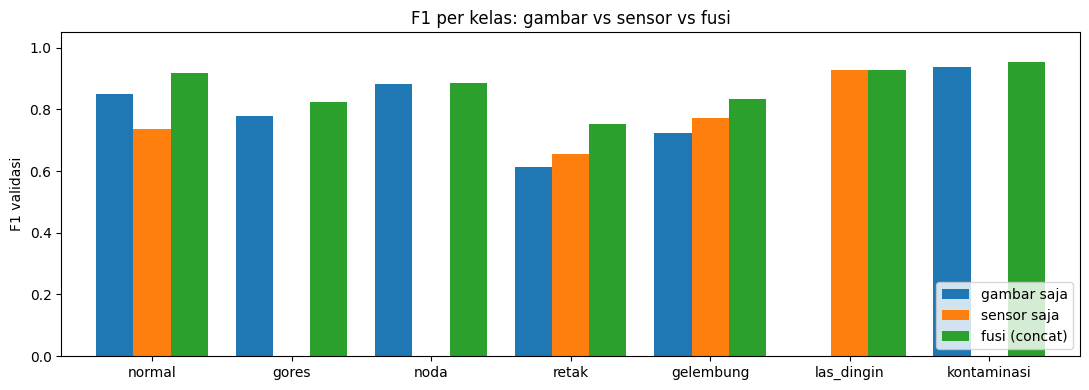

,macro_f1,f1_testmix,f1_A,f1_B,f1_sensor_hilang,acc
gambar_saja,0.6838,0.6343,0.7180,0.5746,0.6528,0.7863
sensor_saja,0.4415,0.4303,0.4496,0.4175,0.0917,0.6517
fusi_concat,0.8708,0.8315,0.8987,0.7855,0.6557,0.8888


In [ ]:
run('gambar_saja', 'img', mod_drop=0.0)
run('sensor_saja', 'sen', mod_drop=0.0)

comp = pd.DataFrame({'gambar saja': RESULTS['gambar_saja']['per_class'],
                     'sensor saja': RESULTS['sensor_saja']['per_class'],
                     f'fusi ({BEST_MODE})': RESULTS[f'fusi_{BEST_MODE}']['per_class']}, index=CLASSES)

def butuh(r):
    gi, ss, fu = r.iloc[0], r.iloc[1], r.iloc[2]
    if gi - ss > 0.15: s = 'gambar'
    elif ss - gi > 0.15: s = 'sensor'
    elif max(gi, ss) < fu - 0.05: s = 'keduanya (saling melengkapi)'
    else: s = 'keduanya cukup'
    return s
comp['modalitas yang dibutuhkan'] = comp.apply(butuh, axis=1)
display(comp.style.format({c: '{:.3f}' for c in comp.columns[:3]}))

ax = comp.iloc[:, :3].plot.bar(figsize=(11, 4), rot=0, width=.8)
ax.set_ylabel('F1 validasi'); ax.set_title('F1 per kelas: gambar vs sensor vs fusi'); ax.set_ylim(0, 1.05)
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()
display(results_table(['gambar_saja', 'sensor_saja', f'fusi_{BEST_MODE}']))

In [ ]:
oof = np.zeros((len(idx_tr), N_CLS), dtype=np.float32)
skf = StratifiedKFold(3, shuffle=True, random_state=SPLIT_SEED)
for f, (a, b) in enumerate(skf.split(idx_tr, strat[idx_tr])):
    m, _ = train_model(BEST_MODE, {**CFG, 'epochs': CFG['oof_epochs']}, idx_tr[a], None, seed=100 + f, verbose=True, tag=None)
    oof[b] = predict(m, get_data(CFG['norm']), idx_tr[b])
    del m
print('macro-F1 out-of-fold:', round(macro_f1(y_all[idx_tr], oof.argmax(1)), 4))

def find_label_issues(P, y, margin=0.5):
    t = np.array([P[y == c, c].mean() for c in range(N_CLS)])
    above = P >= t[None, :]
    cand = np.where(above, P, -1)
    j = cand.argmax(1)
    has = above.any(1)
    flag = has & (j != y) & (P[np.arange(len(y)), j] - P[np.arange(len(y)), y] >= margin)
    return flag, j, t

flag, jstar, thr = find_label_issues(oof, y_all[idx_tr])
SUSPECT = idx_tr[flag]
print(f'Dicurigai salah label: {flag.sum()} dari {len(idx_tr)} ({flag.mean():.2%})')
print('Ambang per kelas:', dict(zip(CLASSES, thr.round(3))))

tm = pd.crosstab(pd.Series([CLASSES[i] for i in y_all[idx_tr][flag]], name='label inspektur'),
                 pd.Series([CLASSES[i] for i in jstar[flag]], name='prediksi model'))
display(tm)
rate = pd.Series(flag).groupby(y_all[idx_tr]).mean(); rate.index = CLASSES
print('Proporsi dicurigai per label:'); print(rate.round(4).to_string())

  [concat] ep  1/8 train_loss=1.4076 (5s)
  [concat] ep  5/8 train_loss=0.6810 (24s)
  [concat] ep  8/8 train_loss=0.5654 (39s)
  [concat] ep  1/8 train_loss=1.4267 (5s)
  [concat] ep  5/8 train_loss=0.6855 (24s)
  [concat] ep  8/8 train_loss=0.5731 (39s)
  [concat] ep  1/8 train_loss=1.4023 (5s)
  [concat] ep  5/8 train_loss=0.6889 (24s)
  [concat] ep  8/8 train_loss=0.5530 (39s)
macro-F1 out-of-fold: 0.8432
Dicurigai salah label: 1393 dari 38400 (3.63%)
Ambang per kelas: {'normal': np.float32(0.762), 'gores': np.float32(0.636), 'noda': np.float32(0.81), 'retak': np.float32(0.663), 'gelembung': np.float32(0.766), 'las_dingin': np.float32(0.91), 'kontaminasi': np.float32(0.866)}


prediksi model,gelembung,gores,kontaminasi,las_dingin,noda,normal,retak
label inspektur,,,,,,,
gelembung,0,5,0,0,137,64,0
gores,0,0,8,0,20,233,74
kontaminasi,0,10,0,0,3,8,3
las_dingin,2,0,0,0,0,73,0
noda,85,9,0,0,0,37,3
normal,85,56,0,121,15,0,81
retak,0,143,1,0,2,115,0


Proporsi dicurigai per label:
normal         0.0187
gores          0.0745
noda           0.0351
retak          0.0905
gelembung      0.0751
las_dingin     0.0217
kontaminasi    0.0127


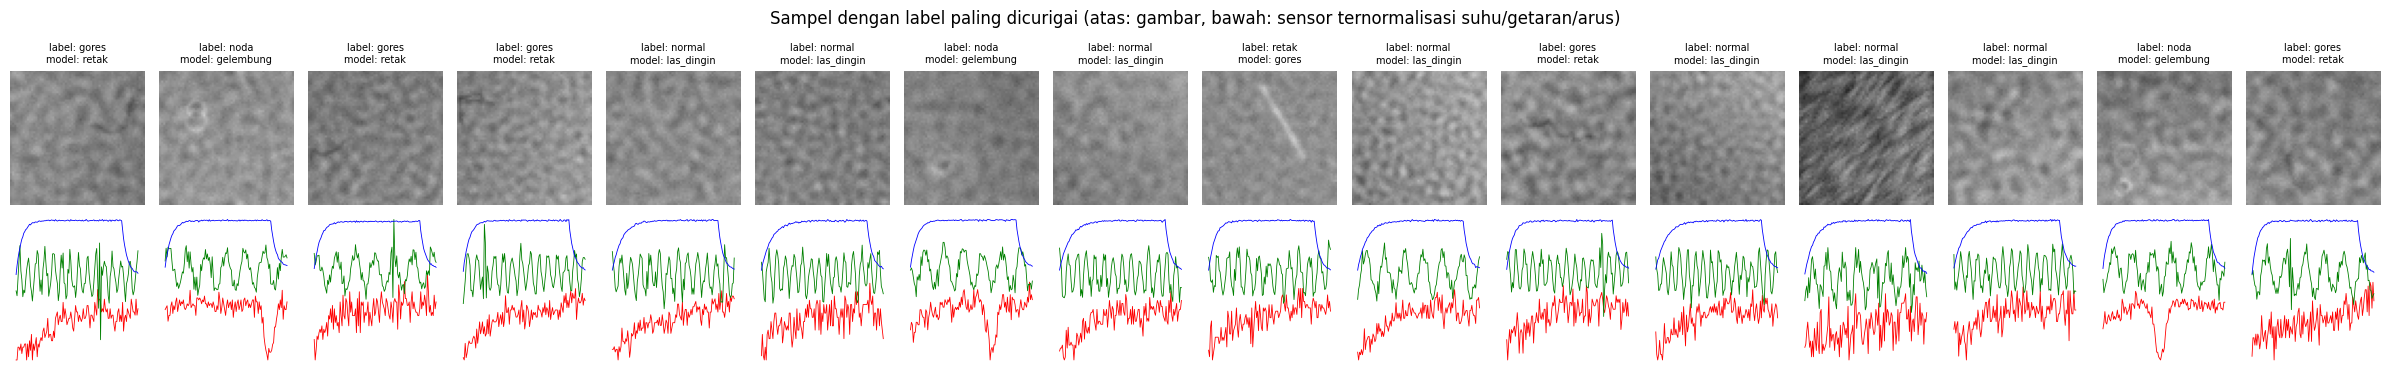

In [ ]:
conf = oof[flag, jstar[flag]] - oof[flag, y_all[idx_tr][flag]]
order = np.argsort(-conf)[:16]
fig, ax = plt.subplots(2, 16, figsize=(24, 3.8))
for c, o in enumerate(order):
    k = SUSPECT[o]
    ax[0, c].imshow(X_img[k], cmap='gray', vmin=0, vmax=255); ax[0, c].axis('off')
    ax[0, c].set_title(f'label: {CLASSES[y_all[k]]}\nmodel: {CLASSES[jstar[flag][o]]}', fontsize=7)
    if present_tr[k]:
        for ch, col in zip(range(3), ['r', 'g', 'b']):
            s = X_sen[k, ch]; ax[1, c].plot((s - np.nanmean(s)) / (np.nanstd(s) + 1e-6) + 3 * ch, col, lw=.6)
    ax[1, c].axis('off')
plt.suptitle('Sampel dengan label paling dicurigai (atas: gambar, bawah: sensor ternormalisasi suhu/getaran/arus)')
plt.tight_layout(); plt.show()

In [ ]:
base_tag = f'fusi_{BEST_MODE}'
run('label_smoothing', BEST_MODE, ls=0.1)
run('buang_label_curiga', BEST_MODE, train_idx=np.setdiff1d(idx_tr, SUSPECT))

fv, _, _ = find_label_issues(PROBS[base_tag], y_all[idx_va])
clean_va = ~fv
print(f'Validasi dicurigai salah label: {fv.sum()} ({fv.mean():.2%})')
rows = {}
for t in [base_tag, 'label_smoothing', 'buang_label_curiga']:
    p = PROBS[t]
    rows[t] = dict(macro_f1=RESULTS[t]['macro_f1'], f1_testmix=RESULTS[t]['f1_testmix'],
                   macro_f1_val_bersih=macro_f1(y_all[idx_va][clean_va], p[clean_va].argmax(1)))
display(pd.DataFrame(rows).T)

USE_LS    = RESULTS['label_smoothing']['f1_testmix'] > RESULTS[base_tag]['f1_testmix']
USE_CLEAN = RESULTS['buang_label_curiga']['f1_testmix'] > RESULTS[base_tag]['f1_testmix']
print('Pakai label smoothing di model akhir:', USE_LS, '| pakai pembersihan:', USE_CLEAN)

  [label_smoothing] ep  1/20 train_loss=1.6253 val_loss=1.0023 val_f1=0.6430 (8s)
  [label_smoothing] ep  5/20 train_loss=1.0682 val_loss=0.5995 val_f1=0.8223 (40s)
  [label_smoothing] ep 10/20 train_loss=0.9746 val_loss=0.5305 val_f1=0.8529 (79s)
  [label_smoothing] ep 15/20 train_loss=0.9091 val_loss=0.5228 val_f1=0.8568 (119s)
  [label_smoothing] ep 20/20 train_loss=0.8612 val_loss=0.4670 val_f1=0.8725 (158s)
[label_smoothing] macroF1=0.8725 | testmix=0.8330 | A=0.9004 | B=0.7869 | sensor-hilang=0.6611
  [buang_label_curiga] ep  1/20 train_loss=1.3619 val_loss=0.8554 val_f1=0.6911 (7s)
  [buang_label_curiga] ep  5/20 train_loss=0.5357 val_loss=0.7374 val_f1=0.7798 (37s)
  [buang_label_curiga] ep 10/20 train_loss=0.4189 val_loss=0.5980 val_f1=0.8394 (75s)
  [buang_label_curiga] ep 15/20 train_loss=0.3435 val_loss=0.5369 val_f1=0.8649 (113s)
  [buang_label_curiga] ep 20/20 train_loss=0.2862 val_loss=0.5391 val_f1=0.8728 (150s)
[buang_label_curiga] macroF1=0.8728 | testmix=0.8331 | A=0

,macro_f1,f1_testmix,macro_f1_val_bersih
fusi_concat,0.8708,0.8315,0.9140
label_smoothing,0.8725,0.8330,0.9148
buang_label_curiga,0.8728,0.8331,0.9148


Pakai label smoothing di model akhir: True | pakai pembersihan: True


  [aug_kecerahan] ep  1/20 train_loss=1.6026 val_loss=0.9602 val_f1=0.6762 (8s)
  [aug_kecerahan] ep  5/20 train_loss=0.9936 val_loss=0.6357 val_f1=0.8081 (38s)
  [aug_kecerahan] ep 10/20 train_loss=0.9015 val_loss=0.5978 val_f1=0.8323 (76s)
  [aug_kecerahan] ep 15/20 train_loss=0.8389 val_loss=0.5059 val_f1=0.8621 (115s)
  [aug_kecerahan] ep 20/20 train_loss=0.7993 val_loss=0.4774 val_f1=0.8682 (153s)
[aug_kecerahan] macroF1=0.8682 | testmix=0.8287 | A=0.8961 | B=0.7824 | sensor-hilang=0.6337
  [norm_per_lini] ep  1/20 train_loss=1.5272 val_loss=0.8692 val_f1=0.7193 (8s)
  [norm_per_lini] ep  5/20 train_loss=0.9801 val_loss=0.7007 val_f1=0.7666 (38s)
  [norm_per_lini] ep 10/20 train_loss=0.8840 val_loss=0.5768 val_f1=0.8360 (76s)
  [norm_per_lini] ep 15/20 train_loss=0.8229 val_loss=0.4886 val_f1=0.8652 (114s)
  [norm_per_lini] ep 20/20 train_loss=0.7784 val_loss=0.4816 val_f1=0.8646 (153s)
[norm_per_lini] macroF1=0.8646 | testmix=0.8224 | A=0.8947 | B=0.7739 | sensor-hilang=0.6468
  

,macro_f1,f1_testmix,f1_A,f1_B
ls+buang_label_curiga,0.8667,0.8266,0.8950,0.7801
aug_kecerahan,0.8682,0.8287,0.8961,0.7824
norm_per_lini,0.8646,0.8224,0.8947,0.7739
norm_per_lini+aug,0.8643,0.8264,0.8911,0.7826


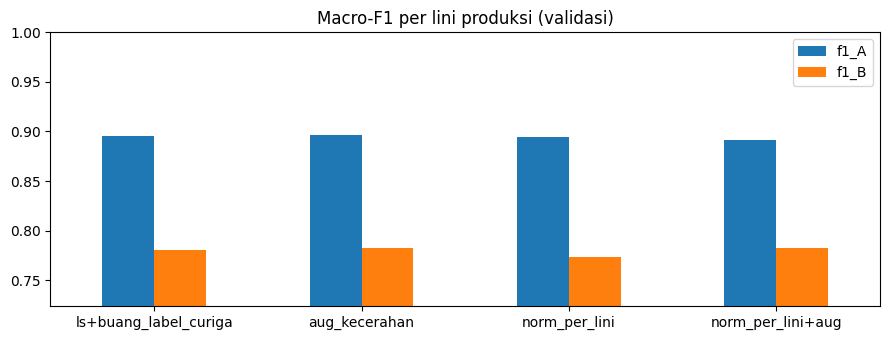

Konfigurasi domain terpilih: aug_kecerahan {'bright_aug': True}


In [ ]:
lab = dict(ls=0.1 if USE_LS else 0.0)
tidx = np.setdiff1d(idx_tr, SUSPECT) if USE_CLEAN else idx_tr
run('aug_kecerahan', BEST_MODE, train_idx=tidx, bright_aug=True, **lab)
run('norm_per_lini', BEST_MODE, train_idx=tidx, norm='line', **lab)
run('norm_per_lini+aug', BEST_MODE, train_idx=tidx, norm='line', bright_aug=True, **lab)

if USE_LS and USE_CLEAN:
    run('ls+buang_label_curiga', BEST_MODE, train_idx=tidx, **lab)
    ref = 'ls+buang_label_curiga'
else:
    ref = 'label_smoothing' if USE_LS else ('buang_label_curiga' if USE_CLEAN else base_tag)
names = [ref, 'aug_kecerahan', 'norm_per_lini', 'norm_per_lini+aug']
dt = results_table(names)[['macro_f1', 'f1_testmix', 'f1_A', 'f1_B']]
display(dt)
ax = dt[['f1_A', 'f1_B']].plot.bar(figsize=(9, 3.5), rot=0); ax.set_ylim(dt[['f1_A', 'f1_B']].values.min() - .05, 1)
ax.set_title('Macro-F1 per lini produksi (validasi)'); plt.tight_layout(); plt.show()

DOMAIN_BEST = max(names, key=lambda n: RESULTS[n]['f1_testmix'])
DOMAIN_CFG = {ref: {}, 'aug_kecerahan': dict(bright_aug=True), 'norm_per_lini': dict(norm='line'),
              'norm_per_lini+aug': dict(norm='line', bright_aug=True)}[DOMAIN_BEST]
print('Konfigurasi domain terpilih:', DOMAIN_BEST, DOMAIN_CFG)

In [ ]:
m_md  = run('fusi_tanpa_mod_dropout', BEST_MODE, mod_drop=0.0)
m_wd  = MODELS[f'fusi_{BEST_MODE}']
m_img = MODELS['gambar_saja']
D = get_data('global')
rows = {}
for nm, mdl in [(f'fusi + mod_dropout {CFG["mod_drop"]}', m_wd), ('fusi tanpa mod_dropout', m_md), ('gambar saja', m_img)]:
    full = predict(mdl, D, idx_va); nos = predict(mdl, D, idx_va, drop_sensor=True)
    yv = y_all[idx_va]; miss = ~present_tr[idx_va]
    rows[nm] = {'F1 sensor lengkap/normal': macro_f1(yv, full.argmax(1)),
                'F1 unit yg sensornya hilang asli': macro_f1(yv[miss], full[miss].argmax(1)),
                'F1 semua sensor dihapus': macro_f1(yv, nos.argmax(1))}
miss_df = pd.DataFrame(rows).T
display(miss_df)

p_no = predict(m_wd, D, idx_va, drop_sensor=True).argmax(1)
p_no2 = predict(m_md, D, idx_va, drop_sensor=True).argmax(1)
dist = pd.DataFrame({'label asli': np.bincount(y_all[idx_va], minlength=N_CLS),
                     'pred (mod_dropout), sensor dihapus': np.bincount(p_no, minlength=N_CLS),
                     'pred (tanpa mod_dropout), sensor dihapus': np.bincount(p_no2, minlength=N_CLS)}, index=CLASSES)
display(dist)

  [fusi_tanpa_mod_dropout] ep  1/20 train_loss=1.3552 val_loss=0.9259 val_f1=0.6549 (8s)
  [fusi_tanpa_mod_dropout] ep  5/20 train_loss=0.6013 val_loss=0.5260 val_f1=0.8139 (39s)
  [fusi_tanpa_mod_dropout] ep 10/20 train_loss=0.4806 val_loss=0.4618 val_f1=0.8428 (78s)
  [fusi_tanpa_mod_dropout] ep 15/20 train_loss=0.3801 val_loss=0.4252 val_f1=0.8528 (117s)
  [fusi_tanpa_mod_dropout] ep 20/20 train_loss=0.2762 val_loss=0.4353 val_f1=0.8601 (156s)
[fusi_tanpa_mod_dropout] macroF1=0.8601 | testmix=0.8175 | A=0.8902 | B=0.7677 | sensor-hilang=0.6246


,F1 sensor lengkap/normal,F1 unit yg sensornya hilang asli,F1 semua sensor dihapus
fusi + mod_dropout 0.15,0.8708,0.6557,0.6542
fusi tanpa mod_dropout,0.8601,0.6246,0.6422
gambar saja,0.6838,0.6528,0.6838


,label asli,"pred (mod_dropout), sensor dihapus","pred (tanpa mod_dropout), sensor dihapus"
normal,4778,5977,5991
gores,1124,1008,967
noda,955,978,983
retak,721,618,654
gelembung,686,565,559
las_dingin,865,0,0
kontaminasi,471,454,446


In [ ]:
FINAL_CFG = {**CFG, 'ls': 0.1 if USE_LS else 0.0, **DOMAIN_CFG}
FINAL_TRAIN = np.setdiff1d(idx_tr, SUSPECT) if USE_CLEAN else idx_tr
print('Mode:', BEST_MODE, '| cfg:', FINAL_CFG, '| n latih:', len(FINAL_TRAIN))
with open(f'{OUT_DIR}/final_config.json', 'w') as f:
    json.dump({'mode': BEST_MODE, 'cfg': FINAL_CFG, 'use_clean': bool(USE_CLEAN), 'seeds': FINAL_SEEDS}, f, indent=2)

final_val_probs, final_test_probs = [], []
for s in FINAL_SEEDS:
    tag = f'final_seed{s}'
    model, _ = train_model(BEST_MODE, FINAL_CFG, FINAL_TRAIN, idx_va, seed=s, tag=tag)
    D = get_data(FINAL_CFG['norm'])
    pv = predict(model, D, idx_va, tta=True)
    evaluate(pv, idx_va, tag)
    final_val_probs.append(pv)
    final_test_probs.append(predict(model, D['test'], np.arange(len(T_img)), tta=True))
    torch.save(model.state_dict(), f'{OUT_DIR}/model_{BEST_MODE}_seed{s}.pt')
    del model

ft = results_table([f'final_seed{s}' for s in FINAL_SEEDS])[['macro_f1', 'f1_testmix', 'f1_A', 'f1_B', 'f1_sensor_hilang', 'acc']]
ft.loc['mean'] = ft.mean(); ft.loc['std'] = ft.iloc[:len(FINAL_SEEDS)].std()
display(ft)
ens = np.mean(final_val_probs, 0)
evaluate(ens, idx_va, 'final_ensemble_3seed')

Mode: concat | cfg: {'epochs': 20, 'oof_epochs': 8, 'batch': 256, 'lr': 0.002, 'wd': 0.0001, 'ls': 0.1, 'mod_drop': 0.15, 'bright_aug': True, 'norm': 'global'} | n latih: 37007
  [final_seed0] ep  1/20 train_loss=1.6026 val_loss=0.9602 val_f1=0.6762 (8s)
  [final_seed0] ep  5/20 train_loss=0.9936 val_loss=0.6357 val_f1=0.8081 (38s)
  [final_seed0] ep 10/20 train_loss=0.9015 val_loss=0.5978 val_f1=0.8323 (76s)
  [final_seed0] ep 15/20 train_loss=0.8389 val_loss=0.5059 val_f1=0.8621 (115s)
  [final_seed0] ep 20/20 train_loss=0.7993 val_loss=0.4774 val_f1=0.8682 (153s)
[final_seed0] macroF1=0.8722 | testmix=0.8350 | A=0.8983 | B=0.7913 | sensor-hilang=0.6427
  [final_seed1] ep  1/20 train_loss=1.6476 val_loss=0.9351 val_f1=0.6813 (8s)
  [final_seed1] ep  5/20 train_loss=0.9940 val_loss=0.5765 val_f1=0.8122 (38s)
  [final_seed1] ep 10/20 train_loss=0.8930 val_loss=0.4949 val_f1=0.8518 (76s)
  [final_seed1] ep 15/20 train_loss=0.8357 val_loss=0.4874 val_f1=0.8642 (115s)
  [final_seed1] ep 2

,macro_f1,f1_testmix,f1_A,f1_B,f1_sensor_hilang,acc
final_seed0,0.8722,0.8350,0.8983,0.7913,0.6427,0.8904
final_seed1,0.8738,0.8343,0.9019,0.7884,0.6637,0.8909
final_seed2,0.8739,0.8360,0.9004,0.7912,0.6573,0.8917
mean,0.8733,0.8351,0.9002,0.7903,0.6546,0.8910
std,0.0010,0.0009,0.0018,0.0016,0.0107,0.0006


[final_ensemble_3seed] macroF1=0.8755 | testmix=0.8381 | A=0.9016 | B=0.7939 | sensor-hilang=0.6649


{'macro_f1': 0.8754509738598221,
 'f1_testmix': 0.8380762267098932,
 'f1_A': 0.9015941410583623,
 'f1_B': 0.7939245919204646,
 'f1_sensor_hilang': 0.6649388951619998,
 'acc': np.float64(0.8932291666666666),
 'per_class': array([0.92050209, 0.83862069, 0.89108911, 0.76211782, 0.8267254 ,
        0.92962744, 0.95947426])}

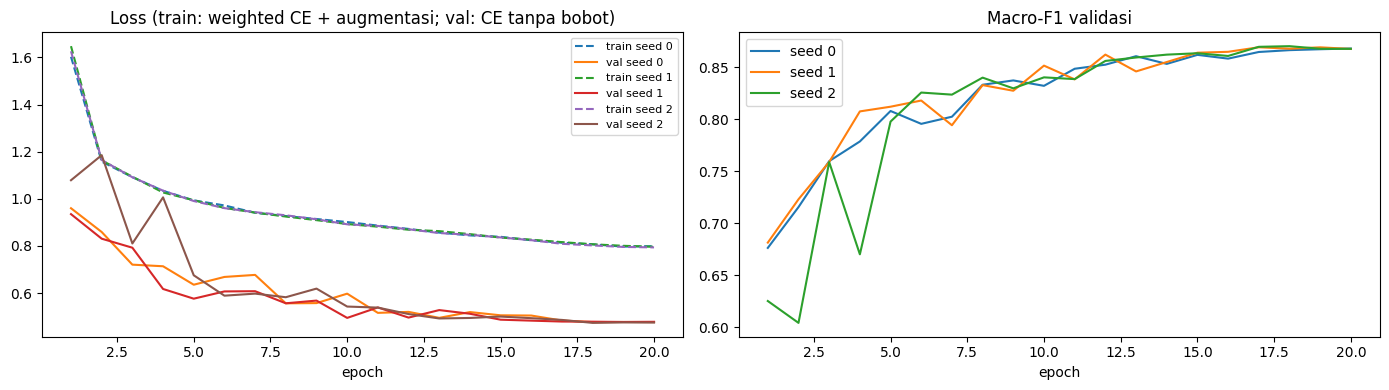

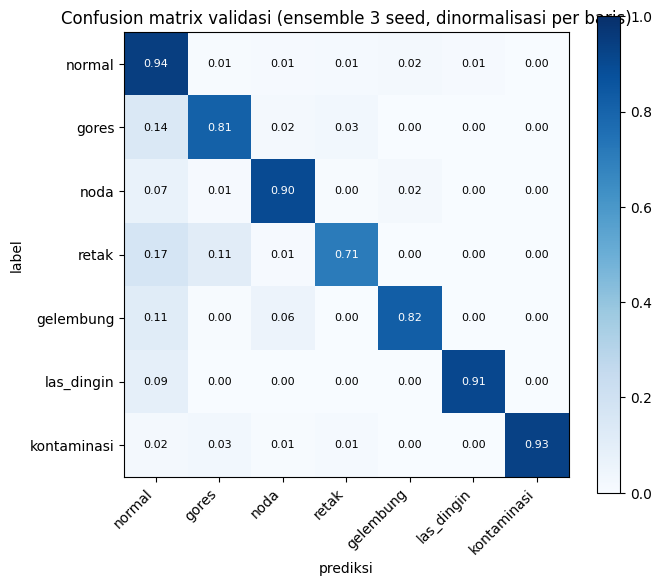

              precision    recall  f1-score   support

      normal     0.8982    0.9439    0.9205      4778
       gores     0.8677    0.8114    0.8386      1124
        noda     0.8869    0.8953    0.8911       955
       retak     0.8242    0.7087    0.7621       721
   gelembung     0.8328    0.8207    0.8267       686
  las_dingin     0.9516    0.9087    0.9296       865
 kontaminasi     0.9910    0.9299    0.9595       471

    accuracy                         0.8932      9600
   macro avg     0.8932    0.8598    0.8755      9600
weighted avg     0.8927    0.8932    0.8921      9600



In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s in FINAL_SEEDS:
    h = HISTS[f'final_seed{s}']
    ax[0].plot(h.epoch, h.train_loss, '--', label=f'train seed {s}')
    ax[0].plot(h.epoch, h.val_loss, label=f'val seed {s}')
    ax[1].plot(h.epoch, h.val_f1, label=f'seed {s}')
ax[0].set_title('Loss (train: weighted CE + augmentasi; val: CE tanpa bobot)'); ax[0].set_xlabel('epoch'); ax[0].legend(fontsize=8)
ax[1].set_title('Macro-F1 validasi'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_all[idx_va], ens.argmax(1), labels=range(N_CLS), normalize='true')
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(N_CLS)); ax.set_xticklabels(CLASSES, rotation=45, ha='right'); ax.set_yticks(range(N_CLS)); ax.set_yticklabels(CLASSES)
for i in range(N_CLS):
    for j in range(N_CLS):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .5 else 'black', fontsize=8)
ax.set_xlabel('prediksi'); ax.set_ylabel('label'); ax.set_title('Confusion matrix validasi (ensemble 3 seed, dinormalisasi per baris)')
plt.colorbar(im); plt.tight_layout(); plt.show()
print(classification_report(y_all[idx_va], ens.argmax(1), target_names=CLASSES, digits=4))

In [ ]:
summary = results_table()[['macro_f1', 'f1_testmix', 'f1_A', 'f1_B', 'f1_sensor_hilang', 'acc']]
display(summary.style.format('{:.4f}').highlight_max(axis=0, color='#c6efce'))
summary.to_csv(f'{OUT_DIR}/ringkasan_eksperimen.csv')
pc = pd.DataFrame({k: v['per_class'] for k, v in RESULTS.items()}, index=CLASSES).T
pc.to_csv(f'{OUT_DIR}/f1_per_kelas.csv')

,macro_f1,f1_testmix,f1_A,f1_B,f1_sensor_hilang,acc
fusi_concat,0.8708,0.8315,0.8987,0.7855,0.6557,0.8888
fusi_late,0.8631,0.8222,0.8919,0.7742,0.6360,0.8838
fusi_xattn,0.8701,0.8265,0.9006,0.7749,0.6458,0.8880
gambar_saja,0.6838,0.6343,0.7180,0.5746,0.6528,0.7863
sensor_saja,0.4415,0.4303,0.4496,0.4175,0.0917,0.6517
label_smoothing,0.8725,0.8330,0.9004,0.7869,0.6611,0.8904
buang_label_curiga,0.8728,0.8331,0.9007,0.7864,0.6383,0.8905
aug_kecerahan,0.8682,0.8287,0.8961,0.7824,0.6337,0.8866
norm_per_lini,0.8646,0.8224,0.8947,0.7739,0.6468,0.8842
norm_per_lini+aug,0.8643,0.8264,0.8911,0.7826,0.6560,0.8838


In [ ]:
test_prob = np.mean(final_test_probs, 0)
pred = pd.DataFrame({'id_unit': te_meta['id_unit'].values,
                     'kelas': [CLASSES[i] for i in test_prob.argmax(1)]})
assert len(pred) == len(te_meta) and pred['id_unit'].is_unique and pred['kelas'].isin(CLASSES).all()
pred.to_csv(f'{OUT_DIR}/prediksi_klasifikasi.csv', index=False)
np.save(f'{OUT_DIR}/test_probs.npy', test_prob)

print(pred.head())
dist = pd.DataFrame({'prediksi test': pred['kelas'].value_counts(normalize=True),
                     'label train': tr_meta['kelas'].value_counts(normalize=True)}).reindex(CLASSES)
display(dist.style.format('{:.2%}'))
print('Distribusi prediksi per lini test:')
display(pd.crosstab(te_meta['lini'], pred['kelas'], normalize='index').reindex(columns=CLASSES).style.format('{:.2%}'))
print('File tersimpan di', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

   id_unit   kelas
0  U412019   gores
1  U929275   gores
2  U845264  normal
3  U382231  normal
4  U156089   gores


,prediksi test,label train
kelas,,
normal,53.78%,49.77%
gores,10.05%,11.71%
noda,9.41%,9.94%
retak,6.52%,7.51%
gelembung,7.24%,7.15%
las_dingin,8.31%,9.01%
kontaminasi,4.68%,4.91%


Distribusi prediksi per lini test:


kelas,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
lini,,,,,,,
A,51.63%,11.36%,9.68%,6.57%,7.66%,8.12%,4.97%
B,55.21%,9.18%,9.23%,6.48%,6.96%,8.44%,4.49%


File tersimpan di /content/outputs : ['f1_per_kelas.csv', 'final_config.json', 'model_concat_seed0.pt', 'model_concat_seed1.pt', 'model_concat_seed2.pt', 'prediksi_klasifikasi.csv', 'ringkasan_eksperimen.csv', 'test_probs.npy']


In [ ]:
try:
    from google.colab import files
    files.download(f'{OUT_DIR}/prediksi_klasifikasi.csv')
except Exception as e:
    print('Unduh manual dari panel Files:', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>